###  02b  Partial quantization e split computing
Questo notebook studia una partizione della VGG11 teacher/student in due segmenti:
- Edge (device): prefisso della rete, con pesi e attivazioni simulati W8A8;
- Fog: suffisso della rete, lasciato FP32;
- Comunicazione: il tensore all'uscita dell'edge viene trasmesso in INT8 e dequantizzato in ingresso al fog. La dequantizzazione è simulata dal FakeQuant 

Vengono provati sia per teacher che student vari livelli di split (secondo i vari layer della rete stessa).

- n_head è il numero di layer di calcolo (conv o Linear) sul dispositivo, da 0 (tutto sul fog, si invia l’immagine) a 11 (tutto sul dispositivo, nessuna trasmissione).

In [1]:
import sys; sys.path.append("..")
%load_ext autoreload
%autoreload 2

import json
import torch, torch.nn as nn
import pandas as pd
from src.data import get_dataloaders
from src.models import build_model
from src.quant import fold_bn, build_w8a8_model
from src.split import (run_split_study, split_tables, plot_split, min_payload_split,
                       save_split, FLASH_KB, SRAM_KB)

device = torch.device("cpu")
train_loader, val_loader, test_loader = get_dataloaders("../data", batch_size=128)

def load_folded(name):
    model = build_model(name)
    model.load_state_dict(torch.load(f"../checkpoints/{name}_baseline.pt", map_location="cpu"))
    return fold_bn(model)

In [ ]:
WITH_TEST = False

studies = {}
for name in ["teacher", "student"]:
    folded = load_folded(name)
    torch.manual_seed(0)
    qmodel, qparams, bias_q = build_w8a8_model(folded, train_loader, n_calib_batches=4)
    df, base_val = run_split_study(folded, qmodel, qparams, bias_q, val_loader,
                                   test_loader if WITH_TEST else None)
    studies[name] = (df, base_val)
    save_split(name, df)
    print()

c:\Users\Pietr\Desktop\Model-Compression\.venv\lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


n_head  0 | input (tutto sul fog)          | val 89.84 | payload  3,072 B | device      0.0 KB | entra: True
n_head  1 | dopo conv1+pool                | val 89.84 | payload 16,384 B | device      2.2 KB | entra: True
n_head  2 | dopo conv2+pool                | val 89.82 | payload  8,192 B | device     77.0 KB | entra: True
n_head  3 | dopo conv3                     | val 89.88 | payload 16,384 B | device    374.0 KB | entra: True
n_head  4 | dopo conv4+pool                | val 89.80 | payload  4,096 B | device    965.8 KB | entra: True
n_head  5 | dopo conv5                     | val 89.82 | payload  8,192 B | device   2149.6 KB | entra: True
n_head  6 | dopo conv6                     | val 89.82 | payload  8,192 B | device   4513.0 KB | entra: False
n_head  7 | dopo conv7                     | val 89.84 | payload  8,192 B | device   6876.4 KB | entra: False
n_head  8 | dopo conv8+pool                | val 89.82 | payload  2,048 B | device   9239.8 KB | entra: False
n_head  9 | dopo

In [3]:
# Controllo di coerenza con i risultati del notebook 02 per split=0 e split completo
print(f"Limiti del device usati per «entra nel device» (ipotesi): flash {FLASH_KB} KB, SRAM {SRAM_KB} KB\n")
for name, (df, _) in studies.items():
    structure, quality = split_tables(df)
    print(f"=== {name}: cosa passa al taglio e quanta rete sta su device e fog ===")
    display(structure)
    print(f"=== {name}: accuracy ed energia aritmetica stimata ===")
    display(quality)

Limiti del device usati per «entra nel device» (ipotesi): flash 4096 KB, SRAM 300 KB

=== teacher: cosa passa al taglio e quanta rete sta su device e fog ===


,taglio,tensore trasmesso,payload (B),payload / immagine,layer su device (%),params su device (%),MACs su device (%),"device (KB, int8)","fog (KB, fp32)",SRAM device (KB),entra nel device
n_head,,,,,,,,,,,
0,input (tutto sul fog),3×32×32,3072,1.00,0.0,0.0,0.0,0.0,62101.0,3.1,sì
1,dopo conv1+pool,64×16×16,16384,5.33,9.0,0.0,0.8,2.2,62093.9,81.9,sì
2,dopo conv2+pool,128×8×8,8192,2.67,18.0,0.5,9.6,77.0,61798.4,81.9,sì
3,dopo conv3,256×8×8,16384,5.33,27.0,2.4,18.3,374.0,60617.8,81.9,sì
4,dopo conv4+pool,256×4×4,4096,1.33,36.0,6.2,35.8,965.8,58257.4,81.9,sì
5,dopo conv5,512×4×4,8192,2.67,45.0,13.8,44.6,2149.6,53536.8,81.9,sì
6,dopo conv6,512×4×4,8192,2.67,55.0,29.0,62.1,4513.0,44097.6,81.9,no
7,dopo conv7,512×4×4,8192,2.67,64.0,44.2,79.6,6876.4,34658.3,81.9,no
8,dopo conv8+pool,512×2×2,2048,0.67,73.0,59.4,97.1,9239.8,25219.1,81.9,no


=== teacher: accuracy ed energia aritmetica stimata ===


,taglio,val acc (%),test acc (%),E device aritm. (µJ),E fog aritm. (µJ)
n_head,,,,,
0,input (tutto sul fog),89.84,NaN,0.00,992.17
1,dopo conv1+pool,89.84,NaN,0.53,984.03
2,dopo conv2+pool,89.82,NaN,6.19,897.21
3,dopo conv3,89.88,NaN,11.86,810.39
4,dopo conv4+pool,89.80,NaN,23.18,636.74
5,dopo conv5,89.82,NaN,28.84,549.92
6,dopo conv6,89.82,NaN,40.17,376.28
7,dopo conv7,89.84,NaN,51.49,202.63
8,dopo conv8+pool,89.82,NaN,62.82,28.99


=== student: cosa passa al taglio e quanta rete sta su device e fog ===


,taglio,tensore trasmesso,payload (B),payload / immagine,layer su device (%),params su device (%),MACs su device (%),"device (KB, int8)","fog (KB, fp32)",SRAM device (KB),entra nel device
n_head,,,,,,,,,,,
0,input (tutto sul fog),3×32×32,3072,1.00,0.0,0.0,0.0,0.0,978.2,3.1,sì
1,dopo conv1+pool,8×16×16,2048,0.67,9.0,0.1,6.2,0.3,977.3,11.3,sì
2,dopo conv2+pool,16×8×8,1024,0.33,18.0,0.6,14.5,1.6,972.6,11.3,sì
3,dopo conv3,32×8×8,2048,0.67,27.0,2.5,22.8,6.4,954.0,11.3,sì
4,dopo conv4+pool,32×4×4,512,0.17,36.0,6.2,39.3,15.9,917.0,11.3,sì
5,dopo conv5,64×4×4,1024,0.33,45.0,13.8,47.6,34.9,843.0,11.3,sì
6,dopo conv6,64×4×4,1024,0.33,55.0,28.9,64.1,72.3,695.3,11.3,sì
7,dopo conv7,64×4×4,1024,0.33,64.0,44.0,80.7,109.6,547.6,11.3,sì
8,dopo conv8+pool,64×2×2,256,0.08,73.0,59.1,97.2,147.0,399.9,11.3,sì


=== student: accuracy ed energia aritmetica stimata ===


,taglio,val acc (%),test acc (%),E device aritm. (µJ),E fog aritm. (µJ)
n_head,,,,,
0,input (tutto sul fog),81.02,NaN,0.00,16.40
1,dopo conv1+pool,80.94,NaN,0.07,15.38
2,dopo conv2+pool,81.02,NaN,0.15,14.02
3,dopo conv3,81.00,NaN,0.24,12.67
4,dopo conv4+pool,81.06,NaN,0.42,9.95
5,dopo conv5,80.98,NaN,0.51,8.60
6,dopo conv6,80.90,NaN,0.69,5.88
7,dopo conv7,80.96,NaN,0.86,3.17
8,dopo conv8+pool,80.96,NaN,1.04,0.46


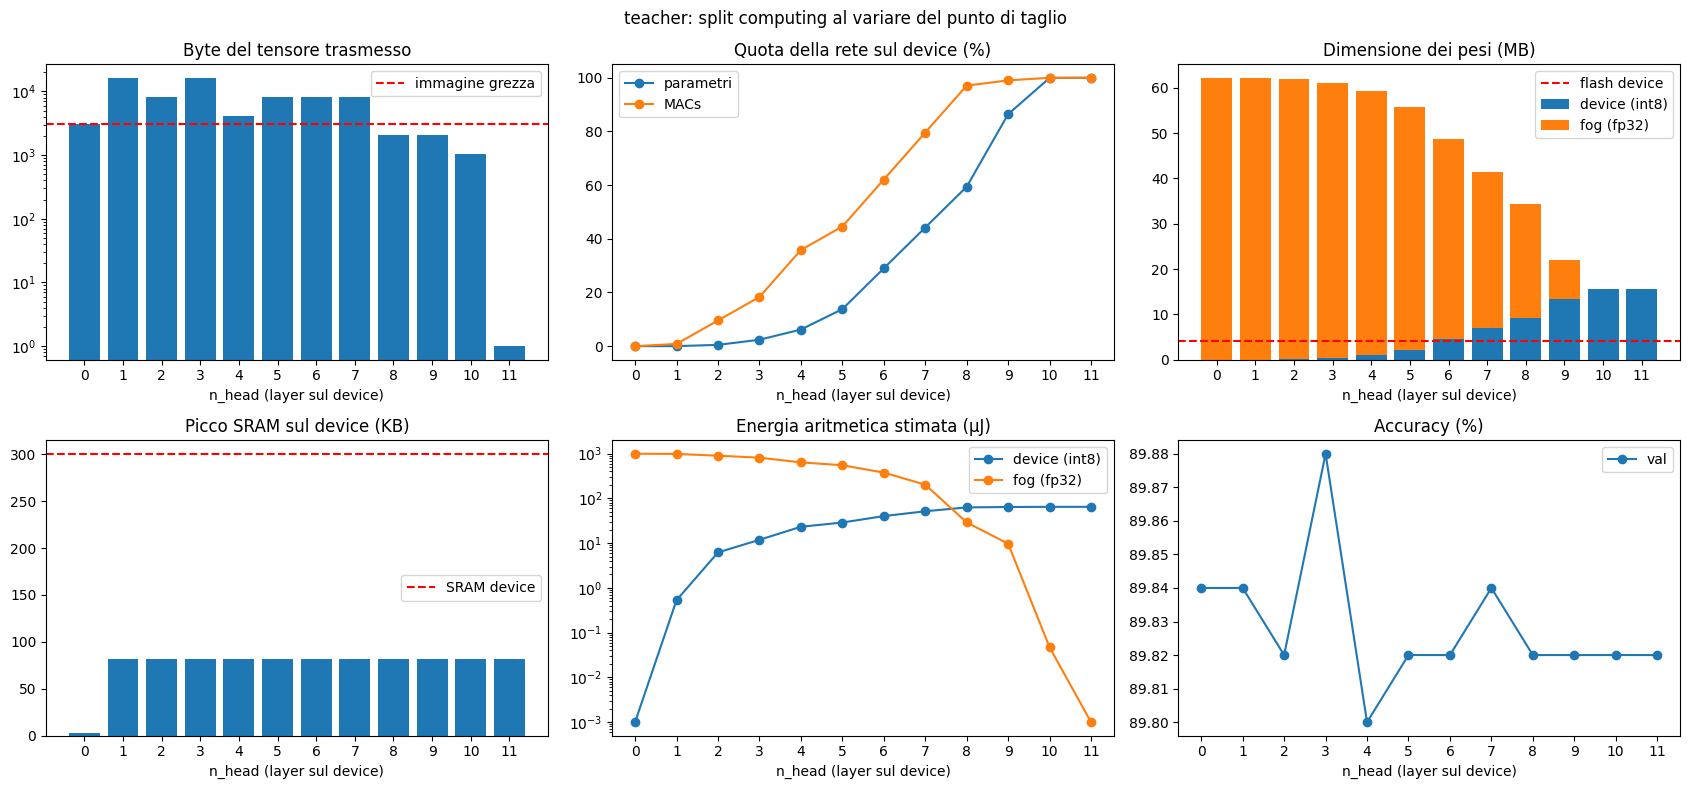

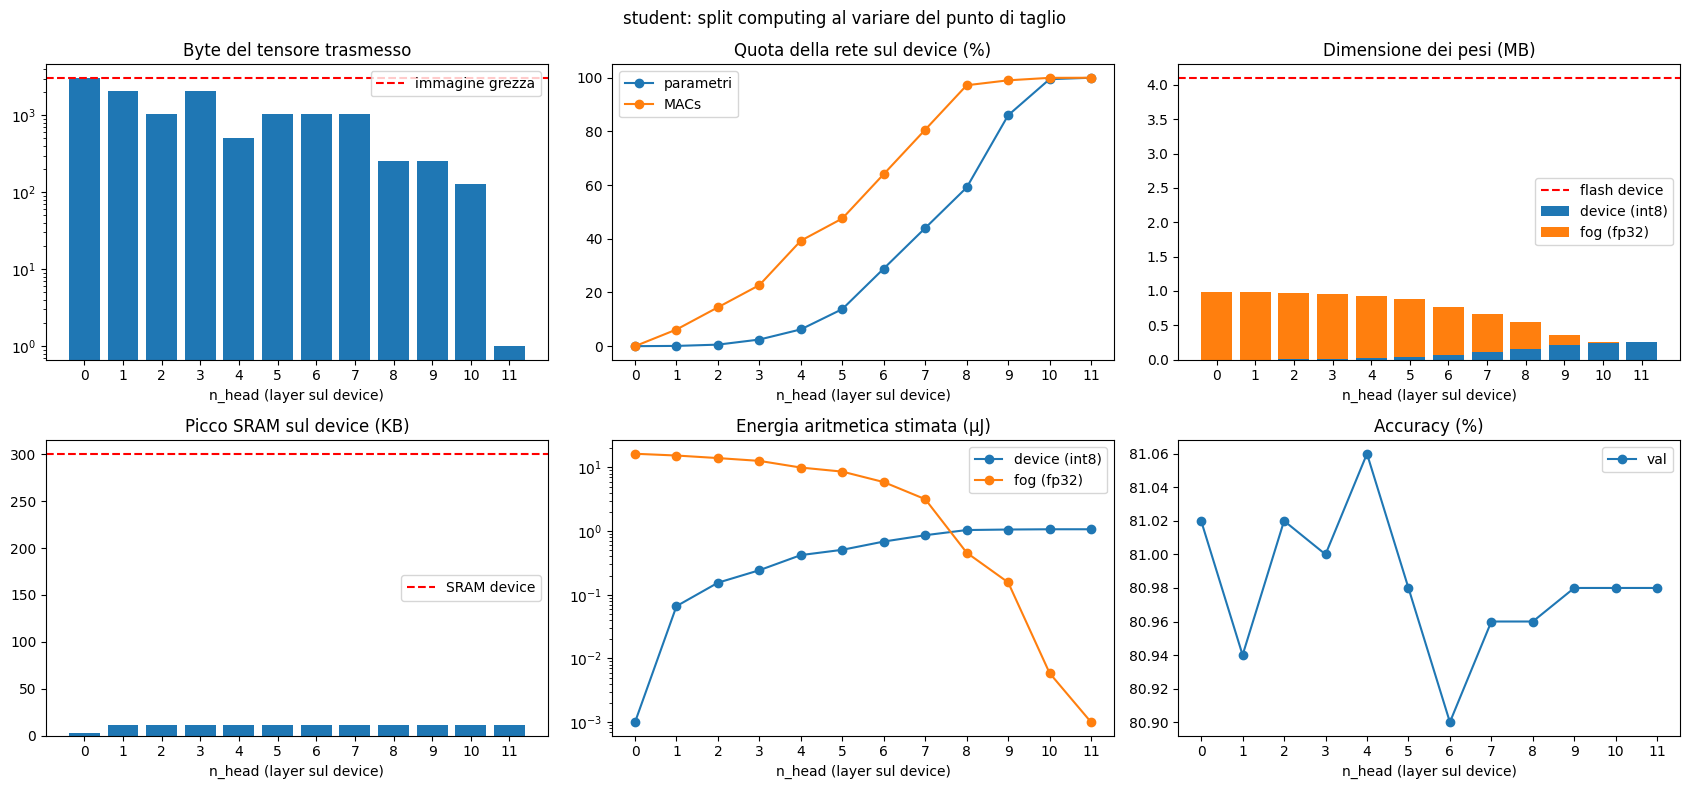

In [4]:
for name, (df, _) in studies.items():
    plot_split(df, f"{name}: split computing al variare del punto di taglio")

In [5]:
# Mostra 3 tagli: 0, intermedio con payload minimo, tutto
rows = []
for name, (df, _) in studies.items():
    picks = [("tutto sul fog", df.iloc[0]),
             ("taglio intermedio, payload minimo", min_payload_split(df)),
             ("tutto sul device", df.iloc[-1])]
    for label, r in picks:
        if r is None:
            continue
        rows.append({
            "modello": name, "scelta": label, "taglio": r["cut"],
            "tensore": r["payload_shape"], "payload (B)": int(r["payload_b"]),
            "params su device (%)": round(100 * r["dev_params"] / (r["dev_params"] + r["fog_params"]), 1),
            "MACs su device (%)": round(100 * r["dev_macs"] / (r["dev_macs"] + r["fog_macs"]), 1),
            "device (KB)": round(r["dev_kb"], 1), "fog (KB)": round(r["fog_kb"], 1),
            "entra nel device": "sì" if r["fits"] else "no",
            "val acc (%)": round(r["val_acc"] * 100, 2),
        })
pd.DataFrame(rows)

,modello,scelta,taglio,tensore,payload (B),params su device (%),MACs su device (%),device (KB),fog (KB),entra nel device,val acc (%)
0,teacher,tutto sul fog,input (tutto sul fog),3×32×32,3072,0.0,0.0,0.0,62101.0,sì,89.84
1,teacher,"taglio intermedio, payload minimo",dopo conv4+pool,256×4×4,4096,6.2,35.8,965.8,58257.4,sì,89.80
2,teacher,tutto sul device,dopo fc3 (tutto sul device),-,0,100.0,100.0,15566.2,0.0,no,89.82
3,student,tutto sul fog,input (tutto sul fog),3×32×32,3072,0.0,0.0,0.0,978.2,sì,81.02
4,student,"taglio intermedio, payload minimo",dopo fc2,128,128,99.5,100.0,248.4,5.2,sì,80.98
5,student,tutto sul device,dopo fc3 (tutto sul device),-,0,100.0,100.0,249.8,0.0,sì,80.98
